# Grid Pulse EV — CEB 2024 and PUCSL reconciliation

**Purpose:** Examine the unresolved difference between PUCSL workbook daily energy summaries and energy integrated from 15-minute reported dispatch. The official **CEB Sales & Generation Data Book 2024**, printed pages **73–74**, is our external benchmark. **Do not interpret accounting discrepancies as renewable curtailment or data correction.**

Primary research period: **2024**. The June 30 PUCSL day is missing; incomplete months are not matched directly to CEB full-month totals. This notebook **does not change existing datasets**. Outputs go under `results/`.

In [1]:
from pathlib import Path
import sys
import subprocess
import pandas as pd
import matplotlib.pyplot as plt

# Works when VS Code opens the notebook from the project root or notebooks/.
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "scripts/reconcile_ceb_2024.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open VS Code at grid-pulse-ev-starter; cannot locate the reconciliation script")
print("Project root:", ROOT)
print("Kernel Python:", sys.executable)

Project root: c:\Users\isuru\Documents\Projects\grid-pulse-ev-starter
Kernel Python: c:\Users\isuru\Documents\Projects\grid-pulse-ev-starter\.venv\Scripts\python.exe


## 1. Check the official CEB source reference

These monthly data were transcribed from the official **gross generation** source table (p. 73) and the **station consumption / net generation** table (p. 74). Gross and net must not be confused. Rooftop-solar figures reflect reported exports rather than total electricity produced and self-consumed behind the meter.

In [2]:
reference = pd.read_csv(ROOT / "docs/ceb_2024_monthly_reference.csv")
ref_cols = ["month_name", "system_gross_generation_gwh", "system_net_generation_gwh",
            "ipp_gross_grid_solar_gwh", "ipp_gross_rooftop_solar_gwh"]
display(reference[ref_cols].round(3))
print("Annual totals (GWh):")
print(reference[ref_cols[1:]].sum().round(3).to_string())
print("Published CEB system annual totals: gross 17460.066 GWh; net 16801.627 GWh")

,month_name,system_gross_generation_gwh,system_net_generation_gwh,ipp_gross_grid_solar_gwh,ipp_gross_rooftop_solar_gwh
0,January,1367.123,1327.964,18.800,53.191
1,February,1376.775,1314.804,21.182,62.091
2,March,1547.343,1477.611,24.595,68.250
3,April,1431.592,1370.372,22.302,72.435
4,May,1484.696,1421.041,17.638,62.840
5,June,1427.374,1372.475,20.143,59.842
6,July,1514.152,1462.121,22.387,67.780
7,August,1512.714,1454.314,22.512,76.805
8,September,1466.853,1408.342,25.516,84.588
9,October,1475.162,1425.070,22.827,85.666


Annual totals (GWh):
system_gross_generation_gwh    17460.067
system_net_generation_gwh      16801.627
ipp_gross_grid_solar_gwh         256.554
ipp_gross_rooftop_solar_gwh      866.553
Published CEB system annual totals: gross 17460.066 GWh; net 16801.627 GWh


## 2. Run the reproducible reconciliation script

This runs against your **existing** consolidated PUCSL 2024 data and monthly reconciliation CSVs. It writes diagnostics to `results/ceb_2024_reconciliation/`; it does not edit any data source.

In [3]:
cmd = [sys.executable, str(ROOT / "scripts/reconcile_ceb_2024.py")]
subprocess.run(cmd, cwd=ROOT, check=True)
outdir = ROOT / "results/ceb_2024_reconciliation"
monthly = pd.read_csv(outdir / "ceb_pucsl_2024_monthly_comparison.csv")
daily = pd.read_csv(outdir / "ceb_pucsl_2024_daily_comparison.csv")
print("Loaded", len(monthly), "months and", len(daily), "daily reconciliation rows")

Loaded 12 months and 336 daily reconciliation rows


## 3. Check completeness before interpreting differences

A full-month official CEB figure should not be compared as if it were equivalent to PUCSL data with missing days. Review-flagged readings are separately tracked, and the script reports both all-observed and clean-only energies.

In [4]:
quality = monthly[["month_name", "expected_intervals", "observed_intervals",
                   "review_required_intervals", "daily_reconciliation_days", "month_status"]]
display(quality)
print("Observed intervals:", int(monthly.observed_intervals.sum()), "of", int(monthly.expected_intervals.sum()))
print("Review-required intervals:", int(monthly.review_required_intervals.sum()))

,month_name,expected_intervals,observed_intervals,review_required_intervals,daily_reconciliation_days,month_status
0,January,2976,2976,118,31.0,complete_observation
1,February,2784,2784,1,29.0,complete_observation
2,March,2976,2976,40,31.0,complete_observation
3,April,2880,2880,0,30.0,complete_observation
4,May,2976,2976,388,31.0,complete_observation
5,June,2880,2784,426,NaN,incomplete_or_missing_daily
6,July,2976,2976,9,31.0,complete_observation
7,August,2976,2976,107,31.0,complete_observation
8,September,2880,2880,17,30.0,complete_observation
9,October,2976,2976,1,31.0,complete_observation


Observed intervals: 35040 of 35136
Review-required intervals: 1263


## 4. Monthly total-energy comparisons — diagnostic only

`dispatch_integrated_all_gwh` integrates the observed 15-minute MW values. `daily_reported_total_gwh` sums the daily energy values in the PUCSL workbooks. CEB `system_gross_generation_gwh` and `system_net_generation_gwh` are **independent, different-boundary** benchmarks. No numerical match is assumed.

In [5]:
total_cols = ["month_name", "month_status", "dispatch_integrated_all_gwh",
              "daily_reported_total_gwh", "system_gross_generation_gwh", "system_net_generation_gwh",
              "daily_total_gap_gwh"]
display(monthly[total_cols].round(3))

,month_name,month_status,dispatch_integrated_all_gwh,daily_reported_total_gwh,system_gross_generation_gwh,system_net_generation_gwh,daily_total_gap_gwh
0,January,complete_observation,1207.248,1296.476,1367.123,1327.964,89.227
1,February,complete_observation,1219.554,1273.754,1376.775,1314.804,54.201
2,March,complete_observation,1400.351,1457.908,1547.343,1477.611,57.558
3,April,complete_observation,1288.571,1357.561,1431.592,1370.372,68.990
4,May,complete_observation,1325.745,1399.427,1484.696,1421.041,73.682
5,June,incomplete_or_missing_daily,1233.460,NaN,1427.374,1372.475,NaN
6,July,complete_observation,1335.972,1429.451,1514.152,1462.121,93.479
7,August,complete_observation,1324.526,1412.396,1512.714,1454.314,87.870
8,September,complete_observation,1275.027,1364.378,1466.853,1408.342,89.351
9,October,complete_observation,1282.927,1374.049,1475.162,1425.070,91.122


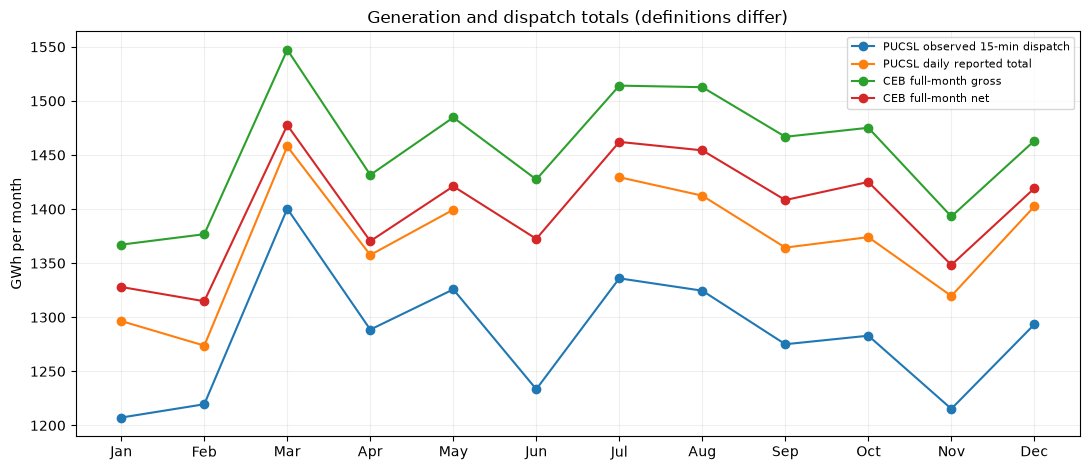

Caution: June 2024 PUCSL observations exclude June 30; full-month CEB totals do not.


In [6]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for col, label in [("dispatch_integrated_all_gwh", "PUCSL observed 15-min dispatch"),
                   ("daily_reported_total_gwh", "PUCSL daily reported total"),
                   ("system_gross_generation_gwh", "CEB full-month gross"),
                   ("system_net_generation_gwh", "CEB full-month net")]:
    ax.plot(monthly.month, monthly[col], marker="o", label=label)
ax.set_xticks(monthly.month, monthly.month_name.str[:3])
ax.set(ylabel="GWh per month", title="Generation and dispatch totals (definitions differ)")
ax.legend(fontsize=8)
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
print("Caution: June 2024 PUCSL observations exclude June 30; full-month CEB totals do not.")

## 5. Test the *solar reporting-boundary hypothesis*

CEB distinguishes **grid-connected solar** from **rooftop exports**. Compare PUCSL integrated 15-minute solar and its daily-reported solar separately with CEB's two source definitions. Differences are retained; **no fixed rooftop-PV correction is applied**.

In [7]:
solar_cols = ["month_name", "solar_integrated_all_gwh", "daily_reported_solar_gwh",
              "ipp_gross_grid_solar_gwh", "ipp_gross_rooftop_solar_gwh", "ceb_gross_total_solar_gwh",
              "daily_solar_gap_gwh", "solar_gap_minus_ceb_rooftop_gwh"]
display(monthly[solar_cols].round(3))

,month_name,solar_integrated_all_gwh,daily_reported_solar_gwh,ipp_gross_grid_solar_gwh,ipp_gross_rooftop_solar_gwh,ceb_gross_total_solar_gwh,daily_solar_gap_gwh,solar_gap_minus_ceb_rooftop_gwh
0,January,14.520,69.527,18.800,53.191,71.991,55.007,1.816
1,February,18.857,62.856,21.182,62.091,83.273,43.998,-18.093
2,March,22.840,76.814,24.595,68.250,92.845,53.974,-14.276
3,April,20.551,84.542,22.302,72.435,94.737,63.991,-8.444
4,May,18.124,85.007,17.638,62.840,80.478,66.883,4.043
5,June,18.432,NaN,20.143,59.842,79.985,NaN,NaN
6,July,18.070,88.740,22.387,67.780,90.167,70.670,2.890
7,August,16.283,78.964,22.512,76.805,99.317,62.681,-14.124
8,September,16.204,85.347,25.516,84.588,110.104,69.143,-15.445
9,October,12.592,95.001,22.827,85.666,108.493,82.408,-3.258


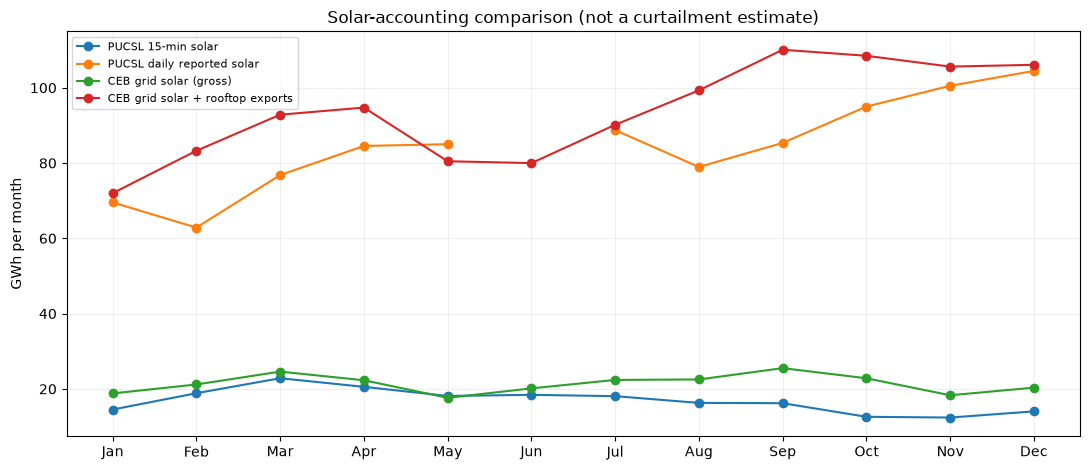

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for col, label in [("solar_integrated_all_gwh", "PUCSL 15-min solar"),
                   ("daily_reported_solar_gwh", "PUCSL daily reported solar"),
                   ("ipp_gross_grid_solar_gwh", "CEB grid solar (gross)"),
                   ("ceb_gross_total_solar_gwh", "CEB grid solar + rooftop exports")]:
    ax.plot(monthly.month, monthly[col], marker="o", label=label)
ax.set_xticks(monthly.month, monthly.month_name.str[:3])
ax.set(ylabel="GWh per month", title="Solar-accounting comparison (not a curtailment estimate)")
ax.legend(fontsize=8)
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 6. Daily source discrepancies and research notes

The residual below is `(PUCSL reported total – PUCSL integrated total) – (PUCSL reported solar – PUCSL integrated solar)`. It is an **unexplained accounting residual**, not proven losses, auxiliary generation, or rooftop PV.

In [9]:
if daily.empty:
    print("No monthly PUCSL reconciliation files were found. Check their location and names.")
else:
    show = ["operating_date", "daily_reported_total_gwh", "daily_integrated_total_gwh",
            "daily_total_gap_gwh", "daily_reported_solar_gwh", "daily_integrated_solar_gwh",
            "daily_solar_gap_gwh", "daily_non_solar_residual_gap_gwh"]
    display(daily[show].head(15).round(4))
    display(daily[show].sort_values("daily_total_gap_gwh", ascending=False).head(10).round(4))
print("Next: verify source definitions with supervisor/CEB before treating any monthly gap as explained.")

,operating_date,daily_reported_total_gwh,daily_integrated_total_gwh,daily_total_gap_gwh,daily_reported_solar_gwh,daily_integrated_solar_gwh,daily_solar_gap_gwh,daily_non_solar_residual_gap_gwh
0,2024-01-01,37.4716,34.2048,3.2668,2.0796,0.1870,1.8926,1.3742
1,2024-01-02,40.9413,37.8352,3.1061,2.1036,0.2798,1.8238,1.2822
2,2024-01-03,42.7574,39.9128,2.8446,2.2804,0.4898,1.7906,1.0540
3,2024-01-04,43.8956,40.9918,2.9038,2.2510,0.4708,1.7802,1.1236
4,2024-01-05,44.3375,41.2403,3.0972,2.2187,0.4235,1.7952,1.3020
5,2024-01-06,41.0692,37.8545,3.2147,2.2545,0.4575,1.7970,1.4177
6,2024-01-07,35.6525,32.4505,3.2020,2.2119,0.3985,1.8134,1.3886
7,2024-01-08,44.0161,40.8500,3.1661,2.0356,0.1325,1.9031,1.2630
8,2024-01-09,44.1347,40.6755,3.4592,2.0558,0.2072,1.8486,1.6106
9,2024-01-10,44.2380,40.7190,3.5190,2.0055,0.0492,1.9562,1.5628


,operating_date,daily_reported_total_gwh,daily_integrated_total_gwh,daily_total_gap_gwh,daily_reported_solar_gwh,daily_integrated_solar_gwh,daily_solar_gap_gwh,daily_non_solar_residual_gap_gwh
181,2024-07-30,47.5289,39.6987,7.8302,2.7480,0.3015,2.4465,5.3836
182,2024-07-31,48.7207,41.4328,7.2880,2.7857,0.4452,2.3404,4.9475
180,2024-07-29,48.2090,41.1425,7.0665,2.7124,0.2492,2.4632,4.6034
183,2024-08-01,48.4282,41.6552,6.7730,2.8410,0.4618,2.3792,4.3937
184,2024-08-02,48.2591,41.9100,6.3491,2.4534,0.3515,2.1019,4.2472
185,2024-08-03,45.4679,39.4540,6.0139,2.5359,0.4670,2.0689,3.9450
179,2024-07-28,42.1229,36.6625,5.4604,2.7644,0.3745,2.3899,3.0705
260,2024-10-17,40.3069,35.7150,4.5919,3.1341,0.5092,2.6248,1.9670
320,2024-12-16,47.3496,43.1810,4.1686,3.1740,0.2170,2.9570,1.2116
318,2024-12-14,41.4537,37.2880,4.1657,3.3416,0.3822,2.9594,1.2064


Next: verify source definitions with supervisor/CEB before treating any monthly gap as explained.
